# Import libraries

In [1]:
# Import pandas, numpy, and matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seaborn is a data visualization library built on matplotlib
import seaborn as sns

# set the plotting style
sns.set_style("whitegrid")

# Model preprocessing
from sklearn.preprocessing import StandardScaler

# Modeling
import statsmodels.formula.api as smf
import statsmodels.api as sm

# Model metrics and analysis
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.anova import anova_lm

# Load clean data

In [2]:
df = pd.read_csv("/Users/anhtuyet15999/Projects/education/data/processed/clean_education.csv")

In [3]:
df.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter,locale,locale_group
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes,21.0,Suburban
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No,31.0,Town
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No,41.0,Rural
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958,Regular School,High,No,32.0,Town
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934,Regular School,High,No,22.0,Suburban


# Modeling

## Single input model using percent_lunch variable
From EDA, we know the percentage of students at the school eligible for free or reduced price lunch (percent_lunch) had the strongest absolute correlation with school average ACT scores among the socioeconomic variables. Therefore, I selected this variable for the single input model to see if it could predict the average ACT score.

### Plot the regression line and the scatter plot

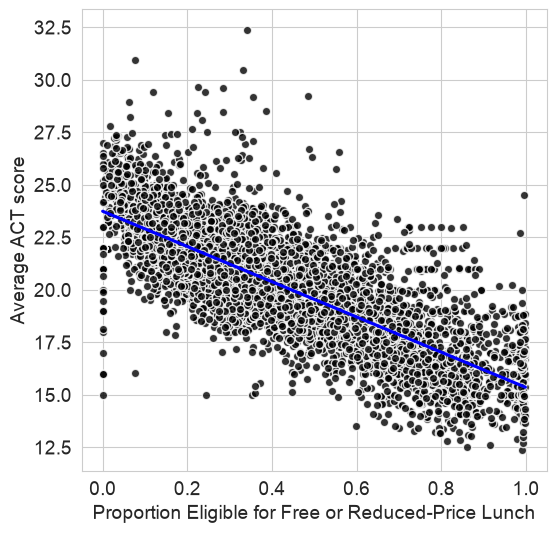

In [4]:
plt.figure(figsize = (6, 6))

sns.regplot(data = df,
           x = 'percent_lunch',
           y = 'average_act',
           color = 'blue',
           ci = False,
           scatter_kws = {'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

# Add axis labels
plt.xlabel('Proportion Eligible for Free or Reduced-Price Lunch', fontsize = 14)
plt.ylabel('Average ACT score', fontsize = 14)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.show()

The scatterplot shows a strong negative, approximately linear association between lunch eligibility and school average ACT scores. Schools with higher proportions of students eligible for free or reduced-price lunch generally have lower average ACT scores.

### Fit the simple linear regression model

In [5]:
model_percent_lunch = smf.ols(formula = 'average_act ~ percent_lunch', data = df).fit()

#### Display the fit summary: check the sign and significance of the coefficients

In [6]:
print(model_percent_lunch.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.614
Model:                            OLS   Adj. R-squared:                  0.614
Method:                 Least Squares   F-statistic:                 1.149e+04
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:01:57   Log-Likelihood:                -13461.
No. Observations:                7227   AIC:                         2.693e+04
Df Residuals:                    7225   BIC:                         2.694e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        23.7429      0.037    641.745

The fitted model is average_act = 23.7429 − 8.3902 × percent_lunch. A 10-percentage-point increase in lunch eligibility is associated with a decrease of approximately 0.84 points in predicted school average ACT score. The coefficient is negative and statistically significant (p = 0.00 < 0.05). The model explains approximately 61.4% (R-squared=0.614) of the variation in school average ACT scores within the sample.

#### Numerical assessment of fit accuracy

##### Compute the the R-squared
R-squared indicates how many the variation in the response variable is explained by the model.

In [7]:
model_percent_lunch.rsquared

np.float64(0.6139194495900617)

##### Compute the RMSE
RMSE measures prediction errors, but penalizes larger errors more heavily.

In [8]:
y_hat = model_percent_lunch.predict()

In [9]:
np.sqrt(mean_squared_error(df['average_act'], y_hat)).round(3)

np.float64(1.559)

##### Compute the mean absolute error (MAE)
MAE measures the average absolute difference between predicted and actual values.

In [10]:
mean_absolute_error(df['average_act'], y_hat)

1.168993937438839

A higher R-squared generally indicates a better fit, while lower RMSE and MAE indicate smaller prediction errors.

The lunch-only model explains approximately 61.4% of the variation in school average ACT scores (R² = 0.614). The MAE is 1.169 points, meaning fitted scores differ from observed scores by about 1.17 points on average in absolute terms. The RMSE is 1.559 points; its higher value reflects greater sensitivity to large errors.

#### Use a residual plot for graphical assessment of model fit
Residual the error between the actual value and the predicted value.

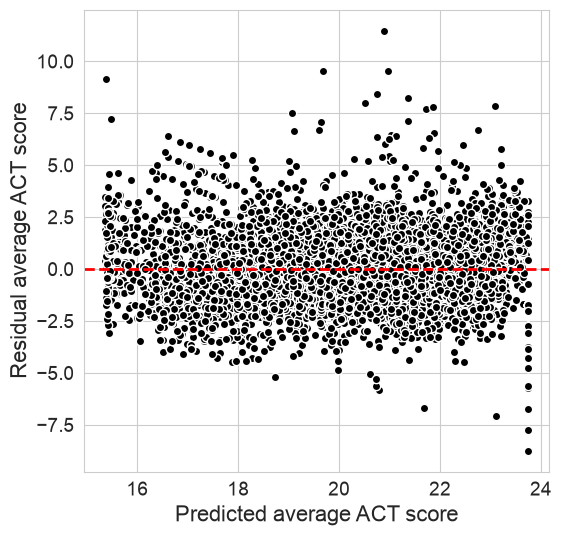

In [11]:
plt.figure(figsize = (6, 6))

plt.plot(y_hat, model_percent_lunch.resid, 'ko', mec = 'w')
plt.axhline(0, color = 'r', linestyle = 'dashed', lw = 2)

# Add axis labels
plt.xlabel('Predicted average ACT score', fontsize = 16)
plt.ylabel('Residual average ACT score', fontsize = 16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.show()

Most residuals are concentrated around zero, with no clear curved pattern. However, several large positive and negative residuals remain, indicating substantial errors for some schools. The large positive residuals show that the model considerably underestimates ACT scores for certain schools. Additional predictors may help explain some of this remaining variation.

### Try a quadratic model. Plot the regression curves and the scatter plot

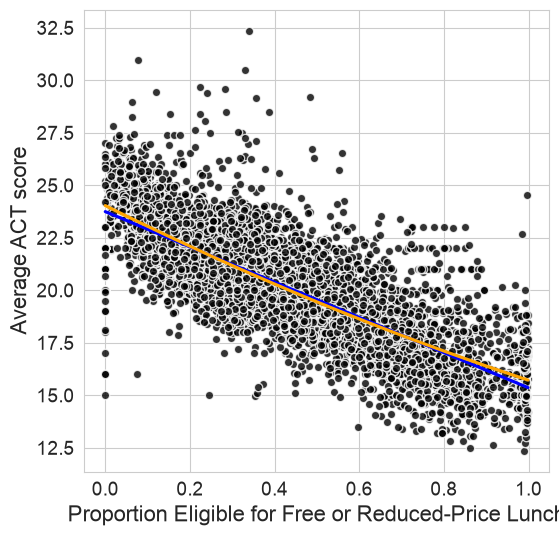

In [12]:
plt.figure(figsize = (6, 6))

sns.regplot(data = df,
           x = 'percent_lunch',
           y = 'average_act',
           color = 'blue',
           ci = False,
           scatter_kws = {'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

sns.regplot(data = df,
           x = 'percent_lunch',
           y = 'average_act',
           order = 2, # compute a quadratic regression line
           color = 'orange',
           ci = False,
           scatter = False)

# Add axis labels
plt.xlabel('Proportion Eligible for Free or Reduced-Price Lunch', fontsize = 16)
plt.ylabel('Average ACT score', fontsize = 16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.show()

The quadratic curve closely follows the linear fit across most of the observed range, with slight upward curvature at both ends. This suggests that the quadratic term captures only a small departure from linearity. The magnitude of improvement is assessed using the model comparison and error metrics below.

### Fit a quadratic linear regression model

In [13]:
model_percent_lunch2 = smf.ols(
    formula = 'average_act ~ percent_lunch + I(percent_lunch**2)', # I is an indicator for the second term
    data = df).fit()

#### Display the fit summary

In [14]:
print(model_percent_lunch2.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.616
Model:                            OLS   Adj. R-squared:                  0.616
Method:                 Least Squares   F-statistic:                     5788.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:01:58   Log-Likelihood:                -13444.
No. Observations:                7227   AIC:                         2.689e+04
Df Residuals:                    7224   BIC:                         2.692e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                24.03

The quadratic model predicts school average ACT scores as 24.0305 − 10.0154x + 1.6991x², where x is the lunch eligibility proportion. The positive quadratic coefficient indicates that predicted ACT scores decrease at a diminishing rate over the observed range. The quadratic term is statistically significant (p < 0.05). However, R² increases only slightly, from 0.614 to 0.616.

#### Assess the model significance

In [15]:
model_percent_lunch2.pvalues

Intercept                 0.000000e+00
percent_lunch            1.867174e-246
I(percent_lunch ** 2)     4.256607e-09
dtype: float64

Both the linear and quadratic terms are statistically significant under conventional OLS standard errors (p < 0.001). The quadratic term provides evidence of curvature in the relationship between lunch eligibility and school average ACT scores. Its practical contribution is assessed through changes in model fit and error metrics.

### Compare two nested polynomial linear regression models: simpler model vs more complicated model

In [16]:
anova_lm(model_percent_lunch, model_percent_lunch2)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7225.0,17553.938543,0.0,NaN,NaN,NaN
1,7224.0,17470.292930,1.0,83.645613,34.587623,4.256607e-09


The partial F-test indicates that adding the quadratic term significantly improves model fit (F = 34.59, p < 0.001). However, the residual sum of squares decreases by only about 0.48%, suggesting a small improvement in in-sample fit. The error metrics below help assess whether this improvement is practically meaningful.

### Compare the quadractic model accuracy to the first order model

In [17]:
mean_absolute_error(df['average_act'], model_percent_lunch2.predict())

1.1651018457233175

In [18]:
mean_absolute_error(df['average_act'], model_percent_lunch.predict())

1.168993937438839

The quadratic model reduces MAE from 1.1690 to 1.1651, an improvement of approximately 0.0039 ACT points (0.33%). Despite the statistically significant quadratic term, the reduction in error is very small. The linear model is therefore retained as the simpler single-predictor model.

## Multiple Linear Regression with Socioeconomic Predictors

### Full Socioeconomic Model

In [19]:
model = smf.ols(
    formula = 'average_act ~ rate_unemployment + percent_college + percent_married + median_income + percent_lunch',
    data = df).fit()

#### Print the summary

In [20]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     2438.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:01:58   Log-Likelihood:                -13328.
No. Observations:                7227   AIC:                         2.667e+04
Df Residuals:                    7221   BIC:                         2.671e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.6972      0.13

The full socioeconomic model explains approximately 62.8% of the variation in school average ACT scores, compared with 61.4% for the lunch-only model. Holding the other predictors constant, a 10-percentage-point increase in unemployment or lunch eligibility is associated with decreases of approximately 0.23 and 0.76 ACT points, respectively. A corresponding increase in college proportion is associated with an increase of approximately 0.17 points. These three coefficients are statistically significant (p < 0.05). Married-couple family proportion and household income do not show statistically significant conditional associations (p > 0.05), motivating evaluation of a reduced model.

#### Use a residual plot for graphical assessment of model fit

In [21]:
y_hat = model.predict()

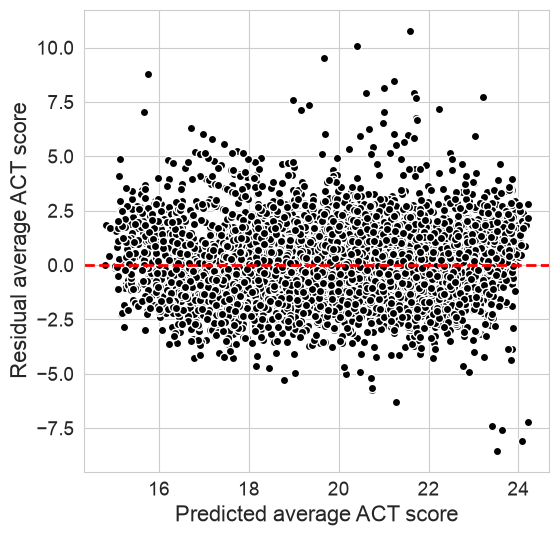

In [22]:
plt.figure(figsize = (6, 6))

plt.plot(y_hat, model.resid, 'ko', mec = 'w')
plt.axhline(0, color = 'r', linestyle = 'dashed', lw = 2)

# Add axis labels
plt.xlabel('Predicted average ACT score', fontsize = 16)
plt.ylabel('Residual average ACT score', fontsize = 16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.show()

The residuals are broadly centered around zero, with no clear curved pattern. However, several large positive and negative residuals indicate substantial prediction errors for some schools. The plot supports a linear model as a reasonable starting point but does not establish constant error variance or rule out improvements from alternative specifications.

#### Compute the mean absolute error

In [23]:
mean_absolute_error(df['average_act'], model.predict())

1.1453304788884031

#### Summary
1. The full socioeconomic model explains approximately 62.8% of the variation in school average ACT scores.
2. Its in-sample MAE is 1.1453 ACT points, compared with 1.1690 for the lunch-only model, indicating a modest improvement.
3. Unemployment, college proportion, and lunch eligibility have statistically significant coefficients (p < 0.05). Household income and married-couple family proportion do not show significant conditional associations.
4. Large residuals remain for some schools. A reduced model is examined next to determine whether a simpler specification can retain similar fit.

### Reduced Socioeconomic Model

In [24]:
model_reduced = smf.ols(
    formula = 'average_act ~ rate_unemployment + percent_college + percent_lunch',
    data = df).fit()

#### Print the summary

In [25]:
print(model_reduced.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     4063.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:01:58   Log-Likelihood:                -13328.
No. Observations:                7227   AIC:                         2.666e+04
Df Residuals:                    7223   BIC:                         2.669e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.6400      0.10

The reduced model explains approximately 62.8% of the variation in school average ACT scores, nearly matching the full socioeconomic model. Holding the other predictors constant, a 10-percentage-point increase in unemployment is associated with a 0.22-point decrease in predicted ACT score, while the same increase in college proportion is associated with a 0.17-point increase. A corresponding increase in lunch eligibility is associated with a 0.76-point decrease. All three coefficients are statistically significant (p < 0.05).

#### Use a residual plot for graphical assessment of model fit

In [26]:
y_hat = model_reduced.predict()

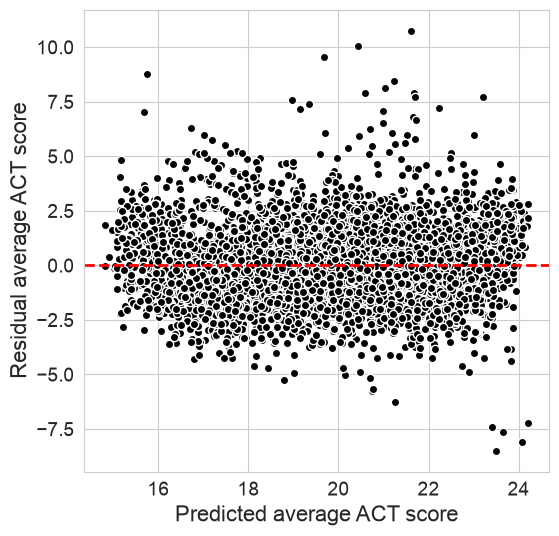

In [27]:
plt.figure(figsize = (6, 6))

plt.plot(y_hat, model_reduced.resid, 'ko', mec = 'w')
plt.axhline(0, color = 'r', linestyle = 'dashed', lw = 2)

# Add axis labels
plt.xlabel('Predicted average ACT score', fontsize = 16)
plt.ylabel('Residual average ACT score', fontsize = 16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.show()

The reduced model shows a residual pattern very similar to that of the full model. Residuals are broadly centered around zero, with no clear curvature, although several large errors remain. Removing household income and married-couple family proportion does not visibly worsen the residual pattern. The numerical comparison below assesses whether the simpler model retains similar fit.

#### Compute the mean absolute error

In [28]:
mean_absolute_error(df['average_act'], model_reduced.predict())

1.1454832950346379

#### Summary
The reduced model achieves an in-sample MAE of 1.1455 ACT points, almost identical to the full model’s MAE of 1.1453. It also retains a similar R² and residual pattern while using only three predictors. These results support considering the reduced model as a simpler alternative. The following ANOVA comparison assesses whether the two additional predictors significantly improve model fit.

### Full vs. Reduced Socioeconomic Model Comparison

In [29]:
mae_full = mean_absolute_error(df['average_act'], model.predict())
mae_reduced = mean_absolute_error(df['average_act'], model_reduced.predict())

r2_full = model.rsquared
r2_reduced = model_reduced.rsquared

pd.DataFrame({'Mean Absolute Error': [mae_full, mae_reduced],
             'R-squared': [r2_full, r2_reduced]},
            index = ['full model', 'reduced model']).round(4)

,Mean Absolute Error,R-squared
full model,1.1453,0.6280
reduced model,1.1455,0.6279


#### Use an ANOVA to test the significance of difference between models

In [30]:
anova_lm(model_reduced, model)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7223.0,16916.619167,0.0,NaN,NaN,NaN
1,7221.0,16915.612457,2.0,1.006711,0.214874,0.806648


#### Summary
The full and reduced models have nearly identical in-sample performance: MAE is 1.1453 versus 1.1455, and R² is 0.6280 versus 0.6279. The partial F-test provides no evidence that adding married-couple family proportion and household income improves model fit (F = 0.215, p = 0.807). The reduced model is therefore preferred at this stage because it achieves similar fit with fewer predictors. School locale is examined next to assess its additional contribution.

## Multiple Linear Regression - Adding School Locale

### Full Socioeconomic Model with Locale

In [31]:
model_locale = smf.ols(
    formula = 'average_act ~ rate_unemployment + percent_college + percent_married + median_income + percent_lunch + C(locale_group, Treatment(reference="City"))',
    data = df).fit()

#### Print the summary

In [32]:
print(model_locale.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     1526.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:01:58   Log-Likelihood:                -13323.
No. Observations:                7227   AIC:                         2.666e+04
Df Residuals:                    7218   BIC:                         2.673e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                                               coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------

#### Summary
With City as the reference category, rural and suburban schools have predicted ACT scores approximately 0.17 and 0.12 points lower, respectively, holding the five socioeconomic predictors constant. These differences are statistically significant (p = 0.005 < 0.05 and p = 0.041 < 0.05). The adjusted difference between town and city schools is small and not statistically significant (p = 0.485). These adjusted comparisons differ from the unadjusted comparisons in the EDA. The additional contribution of locale is assessed through the comparisons below.

### Reduced Socioeconomic Model with Locale

In [33]:
model_locale_reduced = smf.ols(
    formula = 'average_act ~ rate_unemployment + percent_college + percent_lunch + C(locale_group, Treatment(reference="City"))',
    data = df).fit()

#### Print the summary

In [34]:
print(model_locale_reduced.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     2035.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:01:58   Log-Likelihood:                -13323.
No. Observations:                7227   AIC:                         2.666e+04
Df Residuals:                    7220   BIC:                         2.671e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                                               coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------

#### Summary
The reduced model with locale retains nearly the same in-sample R² and coefficient estimates as the full model with locale. Holding unemployment, college proportion, and lunch eligibility constant, rural and suburban schools have predicted ACT scores approximately 0.17 and 0.11 points lower than city schools, respectively (p = 0.004 and p = 0.041). The town–city difference is small and not statistically significant (p = 0.491). The stability of these estimates suggests that removing household income and married-couple family proportion has little effect on the fitted locale differences.

### Contribution of School Locale

#### Use an ANOVA to test the significance of difference between model and model_locale

In [35]:
anova_lm(model, model_locale)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7221.0,16915.612457,0.0,NaN,NaN,NaN
1,7218.0,16892.430014,3.0,23.182443,3.301891,0.019439


#### Use an ANOVA to test the significance of difference between model_reduced and model_locale_reduced

In [36]:
anova_lm(model_reduced, model_locale_reduced)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7223.0,16916.619167,0.0,NaN,NaN,NaN
1,7220.0,16892.507025,3.0,24.112142,3.435244,0.016188


The partial F-tests indicate that adding school locale significantly improves fit in both the full socioeconomic model (F = 3.302, p = 0.0194) and the reduced model (F = 3.435, p = 0.0162). However, the residual sum of squares decreases by only about 0.14% in each case. Thus, locale provides a statistically significant but small additional contribution to in-sample model fit.

## Overall Model Comparison and Selection

In [37]:
models = {
    "Lunch only": model_percent_lunch,
    "Lunch quadratic": model_percent_lunch2,
    "Socioeconomic full": model,
    "Socioeconomic reduced": model_reduced,
    "Full + locale": model_locale,
    "Reduced + locale": model_locale_reduced
}

comparison = pd.DataFrame({
    name: {
        "R-squared": fitted.rsquared,
        "Adjusted R-squared": fitted.rsquared_adj,
        "RMSE": np.sqrt(
            mean_squared_error(df["average_act"], fitted.predict(df))
        ),
        "MAE": mean_absolute_error(
            df["average_act"], fitted.predict(df)
        )
    }
    for name, fitted in models.items()
}).T

comparison.round(4).to_excel("/Users/anhtuyet15999/Projects/education/reports/model_comparison.xlsx", index=True, index_label="Model")
display(comparison.round(4))

,R-squared,Adjusted R-squared,RMSE,MAE
Lunch only,0.6139,0.6139,1.5585,1.1690
Lunch quadratic,0.6158,0.6157,1.5548,1.1651
Socioeconomic full,0.6280,0.6277,1.5299,1.1453
Socioeconomic reduced,0.6279,0.6278,1.5300,1.1455
Full + locale,0.6285,0.6281,1.5289,1.1443
Reduced + locale,0.6285,0.6282,1.5289,1.1443


The reduced socioeconomic model is selected for its simplicity and nearly identical in-sample fit to the full model. Although adding locale produces a statistically significant improvement, the reductions in RMSE and MAE are very small. The selected model includes unemployment rate, college proportion, and lunch eligibility. Its performance on unseen data has not been evaluated.

## Scaling - Standardized Coefficient Interpretation

### Scale the predictor variables in the selected model to have mean 0 and standard deviation 1 and add them to the data frame

In [38]:
predictor_variables = ['rate_unemployment', 'percent_college', 'percent_lunch']

In [39]:
# create a list of names of these scaled columns
scaled_columns = [var + '_normalized' for var in predictor_variables]
print(scaled_columns)

['rate_unemployment_normalized', 'percent_college_normalized', 'percent_lunch_normalized']


In [40]:
# standardize/normalize
scaler = StandardScaler().fit(df[predictor_variables])

In [41]:
df[scaled_columns] = scaler.transform(df[predictor_variables])

### Check the mean and standard deviation of the transformed data.

In [42]:
df[scaled_columns].agg(['mean', 'std']).round(3)

,rate_unemployment_normalized,percent_college_normalized,percent_lunch_normalized
mean,-0.0,-0.0,0.0
std,1.0,1.0,1.0


### Fit the multiple linear regression model with the normalized predictors

In [43]:
model_normalized = smf.ols(
    formula = 'average_act ~ rate_unemployment_normalized + percent_college_normalized + percent_lunch_normalized',
    data = df).fit()

### Print the summary

In [44]:
print(model_normalized.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     4063.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:01:59   Log-Likelihood:                -13328.
No. Observations:                7227   AIC:                         2.666e+04
Df Residuals:                    7223   BIC:                         2.669e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

Holding the other predictors constant, a one-standard-deviation increase in unemployment is associated with a 0.123-point decrease in predicted ACT score. Corresponding increases in college proportion and lunch eligibility are associated with a 0.283-point increase and a 1.777-point decrease, respectively. Lunch eligibility has the largest absolute coefficient among the standardized predictors in this model. The intercept of 20.299 represents the predicted ACT score when all three predictors are at their sample means. Standardizing the predictors changes coefficient units but leaves fitted values and model fit unchanged.

### Compare the accurary between the original and normalized models

In [45]:
mae_normalized = mean_absolute_error(df['average_act'], model_normalized.predict())
mae_reduced = mean_absolute_error(df['average_act'], model_reduced.predict())

r2_normalized = model_normalized.rsquared
r2_reduced = model_reduced.rsquared

pd.DataFrame({'Mean Absolute Error': [mae_normalized, mae_reduced],
             'R-squared': [r2_normalized, r2_reduced]},
            index = ['normalized model', 'reduced model']).round(4)

,Mean Absolute Error,R-squared
normalized model,1.1455,0.6279
reduced model,1.1455,0.6279


The original and standardized models have identical in-sample MAE (1.1455) and R² (0.6279). Standardization changes the units of the coefficients without changing fitted values or model fit. Its purpose here is to facilitate comparison of coefficient magnitudes across predictors, rather than improve predictive accuracy.

### Summary
Holding the other predictors constant, a one-standard-deviation increase in lunch eligibility is associated with a 1.777-point decrease in predicted ACT score, compared with a 0.123-point decrease for unemployment and a 0.283-point increase for college proportion. Lunch eligibility therefore has the largest absolute standardized predictor coefficient in the reduced model.
Standardization leaves fitted values and model fit unchanged: in-sample R² remains 0.6279 and MAE remains 1.1455 ACT points.

# Conclusions and Limitations

## Conclusions

1. The reduced socioeconomic model is selected for its simplicity and nearly identical in-sample fit to the full model. Using unemployment rate, college proportion, and lunch eligibility, it explains approximately 62.8% of the variation in school average ACT scores, with an RMSE of 1.530 and an MAE of 1.145 points.
2. Lunch eligibility has the largest absolute coefficient after standardizing the predictors. Higher lunch eligibility and unemployment are associated with lower predicted ACT scores, while higher college proportion is associated with higher predicted scores, holding the other predictors constant.
3. Adding school locale produces a statistically significant but very small improvement in fit. For the reduced model, MAE decreases from 1.1455 to 1.1443. Locale is therefore omitted from the selected model to favor simplicity.

## Limitations

1. All performance metrics are calculated on the data used to fit the models. Predictive performance on unseen schools has not been evaluated.
2. The sample includes 7,227 schools across 20 states, with unequal geographic representation, limiting generalization to all U.S. high schools.
3. Missing socioeconomic values were imputed during data preparation. The regression results do not account for uncertainty introduced by imputation.
4. Large residuals remain for some schools, and unmeasured factors may help explain the remaining variation in ACT scores.
5. The analysis uses school-level observational data. The associations do not establish causation and should not be interpreted as relationships at the individual student level.